<a href="https://colab.research.google.com/github/Nihat0311/NLP/blob/main/Email_routing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
from torch.optim import AdamW

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Aktiv işçi mühit (Device): {device}")

Aktiv işçi mühit (Device): cuda


In [ ]:
!curl -L -o customer-support-ticket-dataset.zip\
  https://www.kaggle.com/api/v1/datasets/download/suraj520/customer-support-ticket-dataset

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100  827k  100  827k    0     0   432k      0  0:00:01  0:00:01 --:--:-- 1313k


In [ ]:
!unzip /content/customer-support-ticket-dataset.zip

Archive:  /content/customer-support-ticket-dataset.zip
  inflating: customer_support_tickets.csv  


In [ ]:
df = pd.read_csv("/content/customer_support_tickets.csv")

categories = ['Technical support', 'Billing', 'Product inquiry', 'Network', 'Account access']

df.drop('Ticket ID', axis=1, inplace=True)

● Ümumi bilet (ticket) sayısı: 8469

● Hər kateqoriyaya (departamentə) düşən nümunə sayısı:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

● Dataset balanslıdırmı?: Bəli, demək olar ki balanslıdır.
● Ortalama bilet mətni uzunluğu (söz sayısı): 46.47


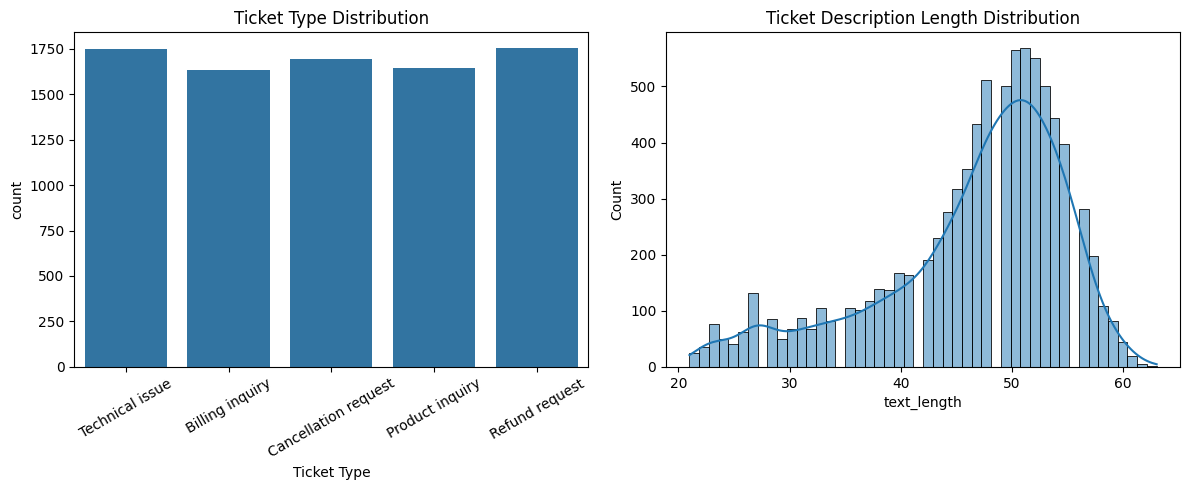

In [ ]:

print(f"● Ümumi bilet (ticket) sayısı: {len(df)}")
print("\n● Hər kateqoriyaya (departamentə) düşən nümunə sayısı:")
print(df['Ticket Type'].value_counts())

print(f"\n● Dataset balanslıdırmı?: {'Bəli, demək olar ki balanslıdır.' if df['Ticket Type'].nunique() == 5 else 'Xeyr'}")

df['text_length'] = df['Ticket Description'].apply(lambda x: len(x.split()))
print(f"● Ortalama bilet mətni uzunluğu (söz sayısı): {df['text_length'].mean():.2f}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Ticket Type')
plt.title("Ticket Type Distribution")
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
sns.histplot(df['text_length'], kde=True)
plt.title("Ticket Description Length Distribution")
plt.tight_layout()
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Customer Name                 8469 non-null   object 
 1   Customer Email                8469 non-null   object 
 2   Customer Age                  8469 non-null   int64  
 3   Customer Gender               8469 non-null   object 
 4   Product Purchased             8469 non-null   object 
 5   Date of Purchase              8469 non-null   object 
 6   Ticket Type                   8469 non-null   object 
 7   Ticket Subject                8469 non-null   object 
 8   Ticket Description            8469 non-null   object 
 9   Ticket Status                 8469 non-null   object 
 10  Resolution                    2769 non-null   object 
 11  Ticket Priority               8469 non-null   object 
 12  Ticket Channel                8469 non-null   object 
 13  Fir

In [ ]:
unique_cats = df['Ticket Type'].unique()
label_map = {cat: i for i, cat in enumerate(unique_cats)}
inv_label_map = {i: cat for cat, i in label_map.items()}
df = df[['Ticket Type', 'Ticket Subject', 'Ticket Description']]
df['label'] = df['Ticket Type'].map(label_map)

/tmp/ipykernel_1050/3620694529.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['label'] = df['Ticket Type'].map(label_map)


In [ ]:
train_df, temp_df = train_test_split(df, test_size=0.20, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

MODEL_NAME = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [ ]:
class TicketDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=512):
        self.texts = texts.values
        self.labels = labels.values
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts[idx])
        inputs = self.tokenizer(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            padding='max_length',
            truncation=True,
            return_tensors='pt'
        )

        return {
            'input_ids': inputs['input_ids'].flatten(),
            'attention_mask': inputs['attention_mask'].flatten(),
            'labels': torch.tensor(self.labels[idx], dtype=torch.long)
        }

train_loader = DataLoader(TicketDataset(train_df['Ticket Description'], train_df['label'], tokenizer), batch_size=16, shuffle=True)
val_loader = DataLoader(TicketDataset(val_df['Ticket Description'], val_df['label'], tokenizer), batch_size=16)
test_loader = DataLoader(TicketDataset(test_df['Ticket Description'], test_df['label'], tokenizer), batch_size=16)

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=len(unique_cats))

model = model.to(device)

import torch.nn as nn
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=1e-5)
epochs = 3
for epoch in range(epochs):
    model.train()
    total_loss = 0

    for batch in train_loader:
        optimizer.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits
        loss = criterion(logits, labels)
        loss.backward()

        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}/{epochs} - Ortalama Loss: {total_loss/len(train_loader):.4f}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/3 - Ortalama Loss: 1.6121
Epoch 2/3 - Ortalama Loss: 1.6102
Epoch 3/3 - Ortalama Loss: 1.6058


In [ ]:
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro')

print(f"\n--- Model Performance on New Dataset ---")
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1-Score:  {f1:.2f}")


--- Model Performance on New Dataset ---
Accuracy:  0.20
Precision: 0.19
Recall:    0.20
F1-Score:  0.16


In [ ]:
def route_ticket(ticket_text, threshold=0.70):
    model.eval()
    inputs = tokenizer(
        ticket_text,
        add_special_tokens=True,
        max_length=128,
        padding='max_length',
        truncation=True,
        return_tensors='pt'
    )

    input_ids = inputs['input_ids'].to(device)
    attention_mask = inputs['attention_mask'].to(device)

    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probabilities = torch.softmax(outputs.logits, dim=1)

        conf, pred_class = torch.max(probabilities, dim=1)
        confidence = conf.item()
        predicted_dept = inv_label_map[pred_class.item()]

    status = "Automatically Routed" if confidence >= threshold else "Human Review Required"

    return {
        "Department/Category": predicted_dept if status == "Automatically Routed" else "None (Under Review)",
        "Confidence": f"{confidence * 100:.1f}%",
        "Status": status
    }
print("\n--- Sistem Yoxlanışı ---")
print(route_ticket("I need a copy of my double charge invoice because I was billed twice.", threshold=0.70))
print(route_ticket("The connection is completely down and my account page is showing a 404 error.", threshold=0.70))


--- Sistem Yoxlanışı ---
{'Department/Category': 'None (Under Review)', 'Confidence': '21.2%', 'Status': 'Human Review Required'}
{'Department/Category': 'None (Under Review)', 'Confidence': '20.9%', 'Status': 'Human Review Required'}


In [ ]:
thresholds = [0.50, 0.70, 0.90]
for t in thresholds:
    auto_routed, human_review = 0, 0
    for text in test_df['Ticket Description']:
        res = route_ticket(text, threshold=t)
        if "Automatically Routed" in res['Status']:
            auto_routed += 1
        else:
            human_review += 1
    print(f"Threshold: {t} -> Auto Routed: {auto_routed} | Human Review: {human_review}")

Threshold: 0.5 -> Auto Routed: 0 | Human Review: 847
Threshold: 0.7 -> Auto Routed: 0 | Human Review: 847
Threshold: 0.9 -> Auto Routed: 0 | Human Review: 847
